<a href="https://colab.research.google.com/github/KeyHornO/Machine-Learning/blob/main/Week6__Assignment_Discovering_Patterns_in_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6: Week 6 Discovering Patterns in Data – Clustering Thermoelectric Measurements
## K-means clustering of the ESTM thermoelectric database

**Name:** Njuguna Benson  

**Course project repo:** https://github.com/KeyHornO/Machine-Learning/tree/main

**Question.** Without telling the algorithm anything about which material is good or bad, do thermoelectric measurements fall into natural groups based on their electrical, thermal and temperature behaviour? Understanding these groups helps me see where SnSe sits among thermoelectric materials, which is the context for my project on improving polycrystalline SnSe.

**Dataset.** The ESTM experimental thermoelectric database (Na & Chang, *npj Computational Materials*, 2022; GitHub `KRICT-DATA/SIMD`): 5,205 measurements of 880 materials. This is a larger dataset than my own 8 SnSe samples, which is too small to cluster.

**Method.** K-means clustering (an unsupervised algorithm), after scaling the features. I choose the number of clusters using the elbow method and the silhouette score.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

URL = "https://raw.githubusercontent.com/KRICT-DATA/SIMD/main/dataset/estm.xlsx"
df = pd.read_excel(URL)
df.columns = ["formula", "T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK", "pf_W_mK2", "zT", "doi"]
print(df.shape)
df.head()

(5205, 8)


,formula,T_K,seebeck_uV_K,sigma_S_m,kappa_W_mK,pf_W_mK2,zT,doi
0,BiSb(Se0.92Br0.08)3,300.0,-110.0,27766.0,0.63,0.000336,0.159985,10.1002/adfm.201806558
1,BiSb(Se0.92Br0.08)3,400.0,-138.0,23883.0,0.57,0.000455,0.319177,10.1002/adfm.201806558
2,BiSb(Se0.92Br0.08)3,500.0,-163.0,20850.0,0.53,0.000554,0.522607,10.1002/adfm.201806558
3,BiSb(Se0.92Br0.08)3,600.0,-181.0,19000.0,0.51,0.000622,0.732305,10.1002/adfm.201806558
4,BiSb(Se0.92Br0.08)3,700.0,-193.0,17925.0,0.50,0.000668,0.940000,10.1002/adfm.201806558


## 1. Features to investigate

| Feature | Meaning | Reason for including it |
|---|---|---|
| `T_K` | Measurement temperature | Behaviour changes strongly with temperature |
| `seebeck_uV_K` | Seebeck coefficient | Its **sign** shows the carrier type (positive = p-type, negative = n-type) and its size reflects the electronic structure |
| `sigma_S_m` | Electrical conductivity | Distinguishes metal-like from semiconductor-like behaviour |
| `kappa_W_mK` | Thermal conductivity | The key quantity limiting thermoelectric efficiency |

**Deliberately left out of the clustering:** `zT` and `pf_W_mK2`. They are calculated from the four features above, so including them would just repeat the same information. Instead I use `zT` **after** clustering, to describe what each group is like, which shows whether the groups are meaningful for performance.

In [2]:
print(df[["T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK"]].describe().round(2))
print("\nMissing values:", int(df[["T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK"]].isna().sum().sum()))
print("Non-positive sigma or kappa:", int((df.sigma_S_m <= 0).sum()), int((df.kappa_W_mK <= 0).sum()))

           T_K  seebeck_uV_K    sigma_S_m  kappa_W_mK
count  5205.00       5205.00      5205.00     5205.00
mean    539.22         73.18    109584.46        2.25
std     192.42        208.92   1467223.91        3.29
min      10.00      -1174.00         0.00        0.07
25%     392.00       -108.32      7059.00        0.73
50%     523.00        100.69     30200.00        1.34
75%     673.00        202.06     91795.00        2.69
max    1275.00       1052.40  94644551.00       77.16

Missing values: 0
Non-positive sigma or kappa: 0 0


## 2. Preparing the features

1. **Log transform for conductivities.** σ spans many orders of magnitude (from near 0 up to about 10⁸ S/m) and is heavily skewed. K-means uses distances, so a few extreme values would dominate. I use log₁₀(σ) and log₁₀(κ), which are also the natural scales for these quantities.
2. **Standardise (scale) all features** to mean 0 and standard deviation 1. Without this, a feature with large numbers (temperature, hundreds of K) would dominate one with small numbers (log κ), since K-means is based on distances.

There are no missing values and no zero or negative conductivities, so no rows need removing.

In [3]:
df["log_sigma"] = np.log10(df["sigma_S_m"])
df["log_kappa"] = np.log10(df["kappa_W_mK"])

features = ["T_K", "seebeck_uV_K", "log_sigma", "log_kappa"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Skewness before/after log transform:")
print(pd.DataFrame({"raw": df[["T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK"]].skew().values,
                    "used": X.skew().values}, index=["T_K", "Seebeck", "sigma", "kappa"]).round(2))
print("\nScaled data: means ~", X_scaled.mean(axis=0).round(2), " std ~", X_scaled.std(axis=0).round(2))

Skewness before/after log transform:
           raw  used
T_K       0.49  0.49
Seebeck  -0.06 -0.06
sigma    56.11 -1.66
kappa     8.93  0.38

Scaled data: means ~ [ 0. -0.  0. -0.]  std ~ [1. 1. 1. 1.]


## 3. Choosing the number of clusters
I run K-means for k = 2 to 10 and compare two measures:
- **Inertia (elbow method):** total squared distance of points to their cluster centre. It always falls as k grows, so I look for the "elbow" where improvement slows.
- **Silhouette score:** how well each point fits its own cluster compared with the nearest other one. It ranges from −1 to 1, and higher means better separated clusters.

,inertia,silhouette
k,,
2,15062.109,0.273
3,12503.766,0.240
4,10461.355,0.263
5,9050.146,0.260
6,7983.614,0.269
7,7405.380,0.271
8,6858.078,0.259
9,6327.731,0.271
10,5913.775,0.266


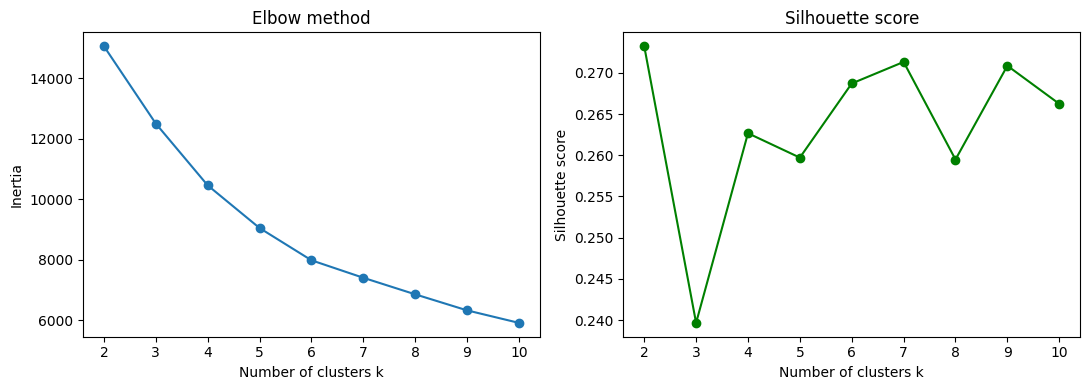

In [4]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

scores = pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).set_index("k")
display(scores.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, marker="o"); ax[0].set(xlabel="Number of clusters k", ylabel="Inertia", title="Elbow method")
ax[1].plot(list(ks), sil, marker="o", color="green"); ax[1].set(xlabel="Number of clusters k", ylabel="Silhouette score", title="Silhouette score")
plt.tight_layout(); plt.show()

### Choice of k
- The **elbow is gradual**, with no sharp bend. The inertia falls steeply up to about k = 4 or 5 and more slowly afterwards.
- The **silhouette scores are low and similar for all k** (about 0.24 to 0.27). This means the measurements do not form sharply separated groups. They form more of a continuum, and the clusters should be read as *regions* of a continuous space, not as distinct species.
- Because the numbers do not point to one clear winner, I choose **k = 4**. It is near the elbow and, as shown below, it gives four groups that are easy to interpret physically. Larger k mostly splits these groups further without adding clearer meaning.

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = kmeans.labels_

# renumber clusters by mean temperature so the numbering is easy to read
order = df.groupby("cluster")["T_K"].mean().sort_values().index
df["cluster"] = df["cluster"].map({old: new for new, old in enumerate(order)})

print("Silhouette score for k = 4:", round(silhouette_score(X_scaled, df["cluster"]), 3))
df["cluster"].value_counts().sort_index()

Silhouette score for k = 4: 0.263


,count
cluster,
0,1418
1,920
2,1604
3,1263


## 4. Visualising the clusters
Two views: (a) the first two **principal components** (PCA), which squash the four features into two axes for plotting, and (b) the physically meaningful plane of **Seebeck coefficient versus conductivity**.

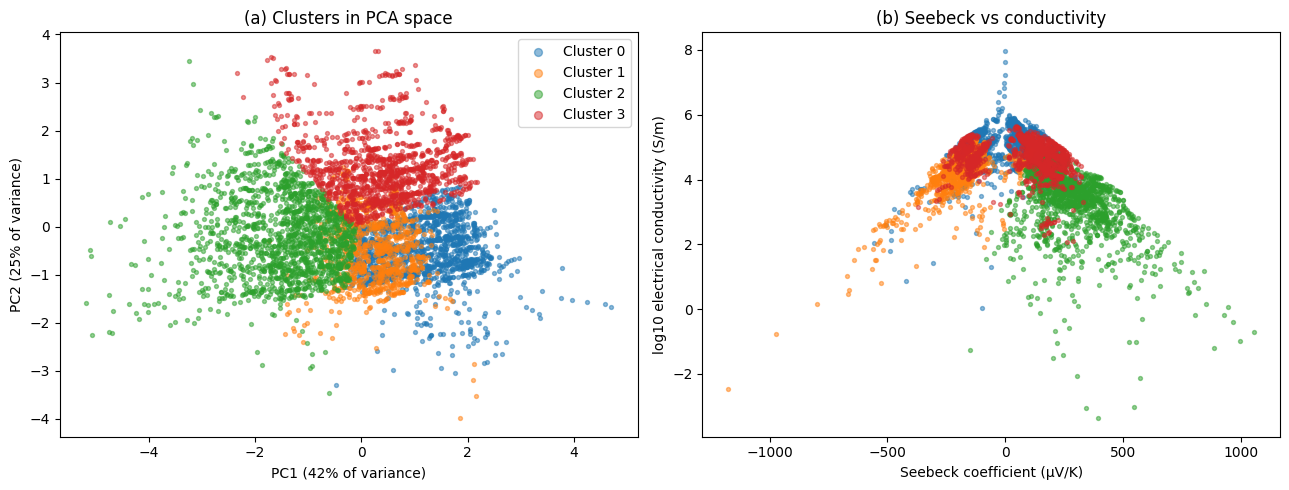

In [6]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
colors = plt.cm.tab10(np.arange(K))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in range(K):
    m = df["cluster"] == c
    ax[0].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, color=colors[c], label=f"Cluster {c}")
    ax[1].scatter(df.loc[m, "seebeck_uV_K"], df.loc[m, "log_sigma"], s=8, alpha=0.5, color=colors[c], label=f"Cluster {c}")
ax[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance)", title="(a) Clusters in PCA space")
ax[1].set(xlabel="Seebeck coefficient (µV/K)", ylabel="log10 electrical conductivity (S/m)", title="(b) Seebeck vs conductivity")
ax[0].legend(markerscale=2); plt.tight_layout(); plt.show()

## 5. Characteristics of the clusters
The table summarises each cluster using the four clustering features, plus `zT` (not used for clustering), the share of p-type rows (positive Seebeck), and the number of **SnSe-based** rows from my project material.

In [7]:
TOKEN = re.compile(r"[A-Z][a-z]?|\d+\.?\d*|\.\d+|\(|\)")
def parse_formula(formula):
    s = formula.replace("[", "(").replace("]", ")").replace(" ", "")
    toks = TOKEN.findall(s)
    if "".join(toks) != s: return None
    num = lambda t: re.fullmatch(r"\d+\.?\d*|\.\d+", t) is not None
    stack, i = [{}], 0
    while i < len(toks):
        t = toks[i]
        if re.fullmatch(r"[A-Z][a-z]?", t):
            n = 1.0
            if i + 1 < len(toks) and num(toks[i + 1]): n = float(toks[i + 1]); i += 1
            stack[-1][t] = stack[-1].get(t, 0) + n
        elif t == "(": stack.append({})
        elif t == ")":
            if len(stack) < 2: return None
            n = 1.0
            if i + 1 < len(toks) and num(toks[i + 1]): n = float(toks[i + 1]); i += 1
            top = stack.pop()
            for el, v in top.items(): stack[-1][el] = stack[-1].get(el, 0) + v * n
        else: return None
        i += 1
    return stack[0] if len(stack) == 1 and stack[0] else None

def is_snse_based(formula):
    a = parse_formula(formula)
    if not a: return False
    sn, se, tot = a.get("Sn", 0), a.get("Se", 0), sum(a.values())
    return sn > 0 and se > 0 and (sn + se) / tot >= 0.9 and 0.8 <= sn / se <= 1.25

df["is_snse"] = df["formula"].apply(is_snse_based)

profile = df.groupby("cluster").agg(
    rows=("zT", "size"),
    mean_T_K=("T_K", "mean"),
    mean_seebeck=("seebeck_uV_K", "mean"),
    median_sigma_S_m=("sigma_S_m", "median"),
    median_kappa=("kappa_W_mK", "median"),
    mean_zT=("zT", "mean"),
    max_zT=("zT", "max"),
    share_p_type=("seebeck_uV_K", lambda s: (s > 0).mean()),
    snse_rows=("is_snse", "sum"),
)
profile.round(2)

,rows,mean_T_K,mean_seebeck,median_sigma_S_m,median_kappa,mean_zT,max_zT,share_p_type,snse_rows
cluster,,,,,,,,,
0,1418,399.85,24.62,118105.5,3.24,0.17,1.06,0.70,0
1,920,483.27,-192.06,19000.0,0.78,0.44,1.53,0.07,0
2,1604,522.44,272.41,4260.0,0.72,0.31,2.28,0.99,154
3,1263,757.75,67.89,60851.0,2.02,0.55,2.03,0.73,0


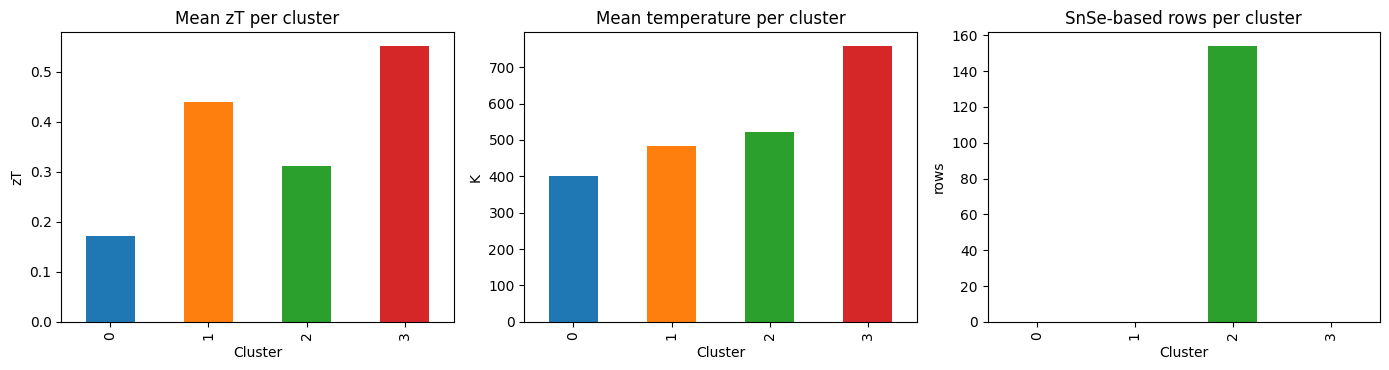

Which materials dominate each cluster (most frequent formulas):
  Cluster 0: ['SnTe', 'GeTe', 'Cu2Se', 'Ag2Se']
  Cluster 1: ['Ag8SiSe6', 'AgBiSe2.0', 'Bi2Te3', 'In4Se2.32Cl0.03']
  Cluster 2: ['SnSe', 'BiCuSeO', 'Cu2.94Ag0.06SbSe4', 'Cu3.0SbSe4']
  Cluster 3: ['SnTe', 'GeTe', 'FeNb0.86Hf0.14Sb', 'FeNb0.88Hf0.12Sb']


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
profile["mean_zT"].plot.bar(ax=ax[0], color=colors[:K]); ax[0].set(title="Mean zT per cluster", xlabel="Cluster", ylabel="zT")
profile["mean_T_K"].plot.bar(ax=ax[1], color=colors[:K]); ax[1].set(title="Mean temperature per cluster", xlabel="Cluster", ylabel="K")
profile["snse_rows"].plot.bar(ax=ax[2], color=colors[:K]); ax[2].set(title="SnSe-based rows per cluster", xlabel="Cluster", ylabel="rows")
plt.tight_layout(); plt.show()

print("Which materials dominate each cluster (most frequent formulas):")
for c in range(K):
    print(f"  Cluster {c}:", df[df.cluster == c]["formula"].value_counts().head(4).index.tolist())

## 6. Discussion

**What the four groups look like**

| Cluster | Rows | What characterises it | Mean zT | Typical materials |
|---|---|---|---|---|
| 0 | 1,418 | Lowest temperatures (mean about 400 K), Seebeck near zero (about 25 µV/K), the **highest conductivity and highest thermal conductivity** (median about 1.2×10⁵ S/m and 3.2 W/m·K), mixed carrier type | 0.17 (lowest) | SnTe, GeTe, Cu₂Se, Ag₂Se |
| 1 | 920 | **n-type** (93% negative Seebeck, mean about −190 µV/K), moderate conductivity, low thermal conductivity (0.78 W/m·K), mid temperatures | 0.44 | Ag₈SiSe₆, AgBiSe₂, Bi₂Te₃ |
| 2 | 1,604 | **p-type** (99% positive Seebeck, mean about +270 µV/K) with the **lowest conductivity** (median about 4×10³ S/m) and low thermal conductivity (0.72 W/m·K) | 0.31 (but the highest single value, 2.28) | **SnSe (all 154 SnSe rows)**, BiCuSeO, Cu₂SbSe₄ derivatives |
| 3 | 1,263 | **Highest temperatures** (mean about 760 K), small Seebeck (about 68 µV/K), high conductivity and moderately high thermal conductivity (2.0 W/m·K) | 0.55 (highest) | SnTe, GeTe, half-Heusler compounds |

**What the clusters might represent**
- The groups are organised mainly by **carrier type, the Seebeck-conductivity trade-off, and temperature**. Plot (b) shows the well-known inverted-V pattern: materials with a large Seebeck coefficient tend to have low conductivity, and vice versa.
- **Cluster 0** looks like metal-like or heavily doped materials measured at low temperature: lots of electrical (and heat) conduction, but little thermopower, so zT is low. **Cluster 1** and **Cluster 2** look like semiconductor-type materials, n-type and p-type respectively. **Cluster 3** looks like a high-temperature regime, where zT is boosted mainly because temperature enters zT directly and carriers are more active. These are interpretations of the table, not something the algorithm was told.
- The same material can appear in different clusters at different temperatures (SnTe and GeTe appear in both Cluster 0 and Cluster 3), because each row is a measurement, not a whole material. So the clusters describe *measurement conditions and behaviour*, not fixed material classes.

**What this means for my SnSe project.** All SnSe-based rows fall in **Cluster 2**, the group with a large Seebeck coefficient, very low thermal conductivity and the lowest electrical conductivity. This agrees with what I found in my own work: SnSe's thermal conductivity is already low, so improving its zT depends on raising electrical conductivity, which is what better texture and higher carrier mobility do. This is consistent with my results but is not proved by the clustering.

**Limitations**
- The **silhouette score is low (about 0.26 for every k)**, and the PCA plot shows the groups overlapping. The data form a continuum, so the boundaries between clusters are somewhat arbitrary, and the choice of k = 4 rests on interpretability as much as on the numbers.
- K-means assumes compact, roughly round clusters, and it is sensitive to which features are chosen and how they are scaled. Different features (for example including composition) would give different groups.
- The data come from published papers, which favour successful, high-performing materials. Exact numbers may differ slightly if the notebook is run with a different version of scikit-learn.
- Clustering describes structure; it does not show cause. It cannot say why SnSe sits where it does.
